# Task 2 — Day-ahead EV charging energy prediction
**Course:** 42577 Introduction to Business Analytics  
**Project:** Powering Palo Alto — EV Charging Operations  
**Prediction:** Gyorkem Yozgyur

### Research question
How much energy will each charging station use in every hour of the next day?

The aim is to predict **24 hourly energy values (kWh) for each station**, using only information available before the day begins. A forecast for a whole day is not enough, because electricity demand changes from hour to hour. The hourly results can help a charging provider plan its energy needs.

The prediction models are compared with a simple **historical average** for the same station, weekday and hour. The data are divided in time order, with about 70% for training and 30% for testing. This follows the requirement of the project.

## 1. Libraries and settings

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TZ = "America/Los_Angeles"
DATA_DIR = Path("Data")
CLEAN_PATH = DATA_DIR / "ev_clean.pkl"
ACTIVITY_PATH = DATA_DIR / "station_active.pkl"
OUTPUT_DIR = DATA_DIR / "forecast_outputs"
GAP_DAYS = 30
EXCLUDE_INFERRED_GAPS = True  # Same sensitivity assumption as preprocessing; see limitations.
VALIDATION_FRACTION_OF_TRAIN = 0.20  # ~56% fit, 14% validation, 30% untouched test.

pd.set_option("display.max_columns", 40)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)
if not CLEAN_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {CLEAN_PATH.resolve()}. First run project.ipynb, Section 1.5, "
        "from the project root to generate Data/ev_clean.pkl."
    )

Python: 3.11.17 | pandas: 3.0.6


## 2. Charging session data
The analysis uses the group's cleaned charging-session data and station activity information. The data cover **July 2011 to February 2020** and contain **245,736 sessions from 33 stations**. Each session has a start time, an end time, a charging duration and total energy in kWh. The times are recorded in local Pacific time. All valid sessions are kept for the energy analysis, including sessions without a known user ID.

In [2]:
ev = pd.read_pickle(CLEAN_PATH).copy()
REQUIRED = {"station", "start", "end", "charging_hours", "energy_kwh"}
missing_columns = sorted(REQUIRED.difference(ev.columns))
if missing_columns:
    raise ValueError(f"Preprocessed data is missing columns: {missing_columns}")

for c in ("start", "end"):
    ev[c] = pd.to_datetime(ev[c], errors="coerce")
    if isinstance(ev[c].dtype, pd.DatetimeTZDtype):
        raise ValueError(f"Expected Pacific local naive timestamps in {c}, but input is tz-aware.")
for c in ("charging_hours", "energy_kwh"):
    ev[c] = pd.to_numeric(ev[c], errors="coerce")
ev["station"] = ev["station"].astype("string").str.strip()

valid = (ev["station"].notna() & ev["station"].ne("") &
         ev["start"].notna() & ev["end"].notna() &
         ev["end"].gt(ev["start"]) &
         ((ev["end"] - ev["start"]) <= pd.Timedelta(hours=24, minutes=1)) &
         ev["charging_hours"].notna() & ev["charging_hours"].gt(0) &
         ev["energy_kwh"].notna() & ev["energy_kwh"].ge(0))
source_quality = pd.DataFrame({
    "check": ["input_sessions", "valid_sessions", "excluded_sessions",
              "excluded_positive_energy_kwh"],
    "value": [len(ev), int(valid.sum()), int((~valid).sum()),
              float(ev.loc[~valid, "energy_kwh"].clip(lower=0).sum())]
})
ev = ev.loc[valid].copy().reset_index(drop=True)
if ev.empty:
    raise ValueError("No valid sessions remain after source audit.")
STATIONS = sorted(ev["station"].unique().tolist())
if len(STATIONS) > 255:
    raise ValueError("More than 255 stations; adjust the boosting categorical encoding.")
START_DAY = ev["start"].min().normalize()
END_EXCLUSIVE = ev["start"].max().normalize() + pd.Timedelta(days=1)
if (END_EXCLUSIVE - START_DAY) < pd.Timedelta(days=45):
    raise ValueError("Fewer than 45 days of data; cannot make a defensible chronological evaluation.")
print(f"Cleaned sessions retained: {len(ev):,} | Stations: {len(STATIONS)}")
print("Cleaned source start dates:", ev["start"].min(), "to", ev["start"].max())
print("Calendar study window:", START_DAY.date(), "to", (END_EXCLUSIVE - pd.Timedelta(days=1)).date())
display(source_quality)

Cleaned sessions retained: 245,736 | Stations: 33
Cleaned source start dates: 2011-07-29 20:17:00 to 2020-02-29 21:47:00
Calendar study window: 2011-07-29 to 2020-02-29


,check,value
0,input_sessions,245736.0
1,valid_sessions,245736.0
2,excluded_sessions,0.0
3,excluded_positive_energy_kwh,0.0


## 3. Converting charging sessions into hourly data
The original data give total energy for each charging session, not measured energy for every hour. To estimate hourly consumption, charging is assumed to start when the vehicle is plugged in and to continue at a constant rate during the recorded charging time. The estimated energy is divided between the hours that overlap the charging period:

$$E_{ih}=E_i\frac{\text{charging seconds of session }i\text{ in hour }h}{\text{total charging seconds of session }i}.$$

Plug occupation is calculated separately. It covers the full time between plugging in and unplugging, including time when the car is no longer charging. A station can have several plugs, so its total occupied minutes can be more than 60 in one hour. The total energy and occupation time are checked after the hourly conversion.

In [3]:
src = ev[["station", "start", "end", "charging_hours", "energy_kwh"]].copy()
requested_end = src["start"] + pd.to_timedelta(src["charging_hours"], unit="h")
src["charging_end"] = pd.concat([requested_end.rename("requested"), src["end"]], axis=1).min(axis=1)
source_active_seconds = (src["charging_end"] - src["start"]).dt.total_seconds()
if (source_active_seconds <= 0).any():
    raise AssertionError("Charging interval with non-positive length remains.")
clipped_n = int((requested_end > src["end"] + pd.Timedelta(seconds=1)).sum())
print("Charging sessions capped at unplug time:", clipped_n)

first_hour = src["start"].dt.floor("h")
last_hour = (src["end"] - pd.Timedelta(nanoseconds=1)).dt.floor("h")
n_hours = ((last_hour - first_hour) / pd.Timedelta(hours=1)).astype("int32") + 1
if n_hours.le(0).any() or n_hours.gt(26).any():
    raise ValueError("Abnormal session hour count; check preprocessing and end dates.")
counts = n_hours.to_numpy(dtype=np.int64)
expanded = src.loc[src.index.repeat(counts)].reset_index(drop=True)
offsets = np.arange(len(expanded), dtype=np.int64) - np.repeat(np.cumsum(counts) - counts, counts)
expanded["timestamp"] = expanded["start"].dt.floor("h") + pd.to_timedelta(offsets, unit="h")
expanded["hour_end"] = expanded["timestamp"] + pd.Timedelta(hours=1)

# Overlap with plug-in interval (occupation), then active-charge interval (energy).
plug_start = pd.concat([expanded["start"], expanded["timestamp"]], axis=1).max(axis=1)
plug_end = pd.concat([expanded["end"], expanded["hour_end"]], axis=1).min(axis=1)
charge_start = plug_start
charge_end = pd.concat([expanded["charging_end"], expanded["hour_end"]], axis=1).min(axis=1)
expanded["occupation_minutes"] = (plug_end - plug_start).dt.total_seconds().clip(lower=0) / 60
expanded["charging_minutes"] = (charge_end - charge_start).dt.total_seconds().clip(lower=0) / 60
expanded["idle_minutes"] = (expanded["occupation_minutes"] - expanded["charging_minutes"]).clip(lower=0)
effective_seconds = (expanded["charging_end"] - expanded["start"]).dt.total_seconds()
expanded["hourly_energy_kwh"] = (expanded["energy_kwh"] *
                                  expanded["charging_minutes"] * 60 / effective_seconds)
# The energy of a previous-day session is not fully known at midnight unless the
# plug-out transaction has completed by that time. This separate, strict feature
# avoids using the final kWh of sessions that finish AFTER the forecast is issued.
known_at_next_midnight = expanded["end"] <= (expanded["timestamp"].dt.normalize() + pd.Timedelta(days=1))
expanded["confirmed_by_next_midnight_kwh"] = expanded["hourly_energy_kwh"].where(
    known_at_next_midnight, 0.0)

source_energy = src["energy_kwh"].sum()
allocated_energy = expanded["hourly_energy_kwh"].sum()
expected_occupation = (src["end"] - src["start"]).dt.total_seconds().sum() / 60
allocated_occupation = expanded["occupation_minutes"].sum()
assert np.isclose(source_energy, allocated_energy, atol=1e-5, rtol=1e-9), "Energy conservation failed."
assert np.isclose(expected_occupation, allocated_occupation, atol=1e-5, rtol=1e-9), "Occupation conservation failed."
assert (expanded[["hourly_energy_kwh", "occupation_minutes", "charging_minutes", "idle_minutes"]].to_numpy() >= -1e-9).all()
print(f"Energy: source {source_energy:,.2f} kWh → hourly {allocated_energy:,.2f} kWh")
print(f"Occupation: source {expected_occupation:,.1f} min → hourly {allocated_occupation:,.1f} min")

observed_hourly = (expanded.loc[expanded["timestamp"].lt(END_EXCLUSIVE)]
    .groupby(["station", "timestamp"], observed=True)
    .agg(energy_kwh=("hourly_energy_kwh", "sum"),
         confirmed_by_next_midnight_kwh=("confirmed_by_next_midnight_kwh", "sum"),
         occupation_minutes=("occupation_minutes", "sum"),
         charging_minutes=("charging_minutes", "sum"),
         idle_minutes=("idle_minutes", "sum"))
    .sort_index())
del expanded, offsets
unconfirmed_total = max(0.0, float(observed_hourly["energy_kwh"].sum() -
                                   observed_hourly["confirmed_by_next_midnight_kwh"].sum()))
print(f"Energy not yet confirmed by the next midnight: {unconfirmed_total:,.2f} kWh")
print(f"Observed station-hours containing any session: {len(observed_hourly):,}")

Charging sessions capped at unplug time: 0
Energy: source 2,099,476.27 kWh → hourly 2,099,476.27 kWh
Occupation: source 37,003,240.8 min → hourly 37,003,240.8 min
Energy not yet confirmed by the next midnight: 107,389.11 kWh
Observed station-hours containing any session: 620,628


## 4. Building the hourly station data
An hourly time series is created for every station between its first and last recorded sessions. Hours with no charging records are treated as **0 kWh** when the station is considered active. Periods outside its recorded activity and gaps longer than 30 days are not treated as zero demand. These long gaps may be related to missing records or changes in station activity, but the exact reason is unknown. This distinction matters because missing data should not be confused with no charging demand.

In [4]:
if ACTIVITY_PATH.is_file():
    activity = pd.read_pickle(ACTIVITY_PATH).copy()
    needed = {"station", "start", "end", "gaps"}
    if not needed.issubset(activity.columns):
        raise ValueError(f"station_active.pkl must contain {sorted(needed)}")
    activity["station"] = activity["station"].astype(str)
    if activity["station"].duplicated().any():
        raise ValueError("station_active.pkl has duplicate station identities.")
    activity = activity.set_index("station")
    print("Using preprocessing activity metadata (including >30-day inferred gaps).")
else:
    print("WARNING: station_active.pkl missing; inferring first/last activity and long gaps from sessions.")
    records = []
    for st, g in ev.sort_values("start").groupby("station", observed=True):
        prev_end = g["end"].cummax().shift()
        gap_mask = (g["start"] - prev_end) > pd.Timedelta(days=GAP_DAYS)
        records.append({"station": st, "start": g["start"].min(), "end": g["end"].max(),
                        "gaps": list(zip(prev_end[gap_mask], g.loc[gap_mask, "start"]))})
    activity = pd.DataFrame(records).set_index("station")

missing_metadata = set(STATIONS) - set(activity.index)
if missing_metadata:
    raise ValueError(f"Station activity metadata missing stations: {sorted(missing_metadata)}")

chunks = []
for st in STATIONS:
    meta = activity.loc[st]
    first = max(pd.Timestamp(meta["start"]).floor("h"), START_DAY)
    after_last = min(pd.Timestamp(meta["end"]).ceil("h"), END_EXCLUSIVE)
    if first >= after_last:
        continue
    local_hours = pd.date_range(first, after_last - pd.Timedelta(hours=1), freq="h")
    active = np.ones(len(local_hours), dtype=bool)
    gaps = meta["gaps"] if isinstance(meta["gaps"], (tuple, list)) else []
    if EXCLUDE_INFERRED_GAPS:
        for gap_start, gap_end in gaps:
            # Exclude whole hours strictly inside a retrospectively inferred long outage.
            active &= ~((local_hours >= pd.Timestamp(gap_start).ceil("h")) &
                        (local_hours < pd.Timestamp(gap_end).floor("h")))
    chunks.append(pd.DataFrame({"station": st, "timestamp": local_hours, "active": active}))
if not chunks:
    raise ValueError("No hourly station panel could be constructed.")
panel = pd.concat(chunks, ignore_index=True)
if panel.duplicated(["station", "timestamp"]).any():
    raise AssertionError("Duplicate station-hour records in panel.")
panel = panel.join(observed_hourly, on=["station", "timestamp"])
for col in ["energy_kwh", "confirmed_by_next_midnight_kwh",
            "occupation_minutes", "charging_minutes", "idle_minutes"]:
    panel[col] = panel[col].fillna(0.0).where(panel["active"], np.nan).astype("float32")
panel["station"] = panel["station"].astype("category")
panel["date"] = panel["timestamp"].dt.normalize()
panel["hour"] = panel["timestamp"].dt.hour.astype("int8")
print("Station-hours:", f"{len(panel):,}", "| active:", f"{panel['active'].sum():,}",
      "| active zero-energy:", f"{((panel['energy_kwh'] == 0) & panel['active']).sum():,}")
display(panel.head(5))

Using preprocessing activity metadata (including >30-day inferred gaps).
Station-hours: 1,321,067 | active: 1,297,220 | active zero-energy: 749,027


,station,timestamp,active,energy_kwh,confirmed_by_next_midnight_kwh,occupation_minutes,charging_minutes,idle_minutes,date,hour
0,PALO ALTO CA / BRYANT #1,2011-10-13 12:00:00,True,0.668822,0.668822,11.000000,11.000000,0.000000,2011-10-13,12
1,PALO ALTO CA / BRYANT #1,2011-10-13 13:00:00,True,0.961686,0.961686,15.933333,15.816667,0.116667,2011-10-13,13
2,PALO ALTO CA / BRYANT #1,2011-10-13 14:00:00,True,0.000000,0.000000,0.000000,0.000000,0.000000,2011-10-13,14
3,PALO ALTO CA / BRYANT #1,2011-10-13 15:00:00,True,0.000000,0.000000,0.000000,0.000000,0.000000,2011-10-13,15
4,PALO ALTO CA / BRYANT #1,2011-10-13 16:00:00,True,0.000000,0.000000,0.000000,0.000000,0.000000,2011-10-13,16


## 5. Complete days and daylight-saving time
The forecast needs 24 hourly values for each station-day. Therefore, the analysis includes only days with 24 hourly records when the station is considered active.

Palo Alto uses daylight-saving time. On the days when the clocks change, the local time can have a missing or repeated hour. Since the cleaned timestamps do not fully explain these changes, **17 clock-change dates** are left out of the target data. After the activity and date checks, **53,706 station-days** remain for the analysis.

In [5]:
# Compute elapsed physical hours between consecutive LOCAL midnights.
# Do NOT divide .asi8 by a fixed nanosecond constant: pandas datetime
# arrays may use ns, us, ms or s units depending on version/input dtype.
midnights = pd.date_range(START_DAY, END_EXCLUSIVE, freq="D", tz=TZ)
day_lengths = np.asarray((midnights[1:] - midnights[:-1]).total_seconds(), dtype=float) / 3600.0
if not np.isin(day_lengths, [23.0, 24.0, 25.0]).all():
    raise ValueError("Unexpected local-day durations; check timezone and calendar inputs.")
DST_DAYS = set(midnights[:-1][~np.isclose(day_lengths, 24.0)].tz_localize(None).normalize())
if len(DST_DAYS) >= max(10, len(day_lengths) // 20):
    raise AssertionError("DST filter excluded too many days; check timestamp units and timezone.")
print("Pacific DST transition days excluded:", len(DST_DAYS), "of", len(day_lengths), "calendar days")

# Explicit per-station / per-date eligibility avoids obscuring which condition fails.
station_day_audit = (panel.groupby(["station", "date"], observed=True)
    .agg(hours=("timestamp", "size"), active_hours=("active", "sum"))
    .reset_index())
station_day_audit["complete_24h"] = station_day_audit["hours"].eq(24)
station_day_audit["all_hours_active"] = station_day_audit["active_hours"].eq(24)
station_day_audit["not_DST"] = ~station_day_audit["date"].isin(DST_DAYS)
station_day_audit["eligible"] = (
    station_day_audit["complete_24h"] &
    station_day_audit["all_hours_active"] &
    station_day_audit["not_DST"]
)

print("\n=== STATION-DAY ELIGIBILITY AUDIT ===")
print("Stations in cleaned sessions:", len(STATIONS))
print("Stations in hourly panel:", panel["station"].nunique())
print("Panel records:", len(panel), "| active hours:", int(panel["active"].sum()))
print("Panel range:", panel["timestamp"].min(), "through", panel["timestamp"].max())
print("Station-day groups:", len(station_day_audit))
for name in ("complete_24h", "all_hours_active", "not_DST", "eligible"):
    print(f"Station-days passing {name}: {int(station_day_audit[name].sum()):,}")
print("Excluded Pacific DST dates (only actual clock changes):", [str(d.date()) for d in sorted(DST_DAYS)])
print("Distribution of hours per station-day (top):")
print(station_day_audit["hours"].value_counts().head(8).to_string())
print("Sample station-day audit:")
display(station_day_audit.head(12))

# Match entire station-days using their original keys rather than broadcasting
# per-hour flags from an indirect groupby transform.
eligible_keys = pd.MultiIndex.from_frame(
    station_day_audit.loc[station_day_audit["eligible"], ["station", "date"]])
panel_keys = pd.MultiIndex.from_frame(panel[["station", "date"]])
panel["eligible_target"] = panel_keys.isin(eligible_keys)
eligible_panel = panel.loc[panel["eligible_target"]]

if eligible_panel.empty:
    raise ValueError(
        "No eligible complete station-days. The audit printed ABOVE shows "
        "whether the issue is missing 24-hour dates, inactive station hours, "
        "or DST filtering. Please share that printed audit plus the output "
        "from the 'Station-hours:' cell. Do NOT relax the complete-day criterion."
    )
day_sizes = eligible_panel.groupby(["station", "date"], observed=True).size()
assert day_sizes.eq(24).all(), "Eligible station-day with !=24 hours."
assert eligible_panel["active"].all(), "Inactive hour incorrectly included."
print("Eligible station-days:", f"{len(day_sizes):,}",
      "| hourly targets:", f"{len(eligible_panel):,}")
print("Eligible station count:", eligible_panel["station"].nunique())

Pacific DST transition days excluded: 17 of 3138 calendar days

=== STATION-DAY ELIGIBILITY AUDIT ===
Stations in cleaned sessions: 33
Stations in hourly panel: 33
Panel records: 1321067 | active hours: 1297220
Panel range: 2011-07-29 20:00:00 through 2020-02-29 23:00:00
Station-day groups: 55068
Station-days passing complete_24h: 55,005
Station-days passing all_hours_active: 53,996
Station-days passing not_DST: 54,775
Station-days passing eligible: 53,706
Excluded Pacific DST dates (only actual clock changes): ['2011-11-06', '2012-03-11', '2012-11-04', '2013-03-10', '2013-11-03', '2014-03-09', '2014-11-02', '2015-03-08', '2015-11-01', '2016-03-13', '2016-11-06', '2017-03-12', '2017-11-05', '2018-03-11', '2018-11-04', '2019-03-10', '2019-11-03']
Distribution of hours per station-day (top):
hours
24    55005
21        7
16        7
20        6
9         5
22        5
13        4
11        4
Sample station-day audit:


,station,date,hours,active_hours,complete_24h,all_hours_active,not_DST,eligible
0,PALO ALTO CA / BRYANT #1,2011-10-13,12,12,False,False,True,False
1,PALO ALTO CA / BRYANT #1,2011-10-14,24,24,True,True,True,True
2,PALO ALTO CA / BRYANT #1,2011-10-15,24,24,True,True,True,True
3,PALO ALTO CA / BRYANT #1,2011-10-16,24,24,True,True,True,True
4,PALO ALTO CA / BRYANT #1,2011-10-17,24,24,True,True,True,True
5,PALO ALTO CA / BRYANT #1,2011-10-18,24,24,True,True,True,True
6,PALO ALTO CA / BRYANT #1,2011-10-19,24,24,True,True,True,True
7,PALO ALTO CA / BRYANT #1,2011-10-20,24,24,True,True,True,True
8,PALO ALTO CA / BRYANT #1,2011-10-21,24,24,True,True,True,True
9,PALO ALTO CA / BRYANT #1,2011-10-22,24,24,True,True,True,True


Eligible station-days: 53,706 | hourly targets: 1,288,944
Eligible station count: 33


## 6. Forecasting variables
The models use the station, hour, weekday, month and weekend information. They also use past energy consumption, including values from **24, 48 and 168 hours earlier**, the average for the same hour over the previous seven days, and the previous day's energy total. Cyclical calendar variables help describe daily and weekly patterns.

The forecast is made at the start of the target day. For yesterday's energy, sessions that were still in progress at midnight are not treated as completed transactions. **No actual consumption from the day being predicted is used as an input.**

In [6]:
STATION_TO_CODE = {st: i for i, st in enumerate(STATIONS)}
LAG_DAYS = (1, 2, 3, 4, 5, 6, 7)

def make_features(ordered_panel):
    df = ordered_panel.sort_values(["station", "timestamp"]).copy()
    df["date"] = df["timestamp"].dt.normalize()
    df["hour"] = df["timestamp"].dt.hour.astype("int8")
    df["dow"] = df["timestamp"].dt.dayofweek.astype("int8")
    df["month"] = df["timestamp"].dt.month.astype("int8")
    df["is_weekend"] = (df["dow"] >= 5).astype("int8")
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24).astype("float32")
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24).astype("float32")
    df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7).astype("float32")
    df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7).astype("float32")
    df["station_code"] = df["station"].astype("string").map(STATION_TO_CODE).astype("int16")
    grouped = df.groupby("station", sort=False, observed=True)
    g = grouped["energy_kwh"]
    # lag_24 requires confirmed-by-midnight energy to avoid cross-midnight
    # transaction leakage. Older lags are final because sessions last <=24 h.
    df["lag_24_confirmed"] = grouped["confirmed_by_next_midnight_kwh"].shift(24).astype("float32")
    for days in LAG_DAYS[1:]:
        df[f"lag_{days*24}"] = g.shift(days * 24).astype("float32")
    lag_cols = ["lag_24_confirmed"] + [f"lag_{d*24}" for d in LAG_DAYS[1:]]
    df["prior_7d_same_hour_mean"] = df[lag_cols].mean(axis=1).astype("float32")
    # Previous-day total: the target day's actual energy is never used as a feature.
    daily = (df.groupby(["station", "date"], observed=True)["confirmed_by_next_midnight_kwh"]
             .sum(min_count=24).rename("daily_kwh").reset_index())
    daily["previous_day_kwh"] = (daily.groupby("station", observed=True)["daily_kwh"]
                                 .shift(1).astype("float32"))
    df = df.merge(daily[["station", "date", "previous_day_kwh"]],
                  on=["station", "date"], how="left", validate="many_to_one", sort=False)
    return df

NUMERIC_FEATURES = ["hour", "dow", "month", "is_weekend", "hour_sin", "hour_cos",
                    "dow_sin", "dow_cos", "lag_24_confirmed", "lag_48", "lag_168",
                    "prior_7d_same_hour_mean", "previous_day_kwh"]
BOOST_FEATURES = ["station_code"] + NUMERIC_FEATURES
RIDGE_FEATURES = ["station"] + NUMERIC_FEATURES
assert all(int(c.split("_")[1]) >= 24 for c in NUMERIC_FEATURES if c.startswith("lag_"))

# Leakage check uses ONLY the project's actual station-hour panel.
# Mask one real target day's outcomes in a temporary copy (not used to fit
# models). Its forecast-issue-time predictors must remain unchanged.
check_station = panel.groupby("station", observed=True).size().idxmax()
fixture = (panel.loc[panel["station"].eq(check_station),
                     ["station", "timestamp", "energy_kwh", "confirmed_by_next_midnight_kwh"]]
           .sort_values("timestamp").head(24 * 15).copy())
fixture_dates = fixture["timestamp"].dt.normalize()
full_fixture_days = fixture_dates.value_counts().loc[lambda counts: counts.eq(24)].sort_index().index
if len(full_fixture_days) < 8:
    raise ValueError("Too little real station history for the feature leakage check.")
check_date = full_fixture_days[7]
original_features = make_features(fixture)
masked_fixture = fixture.copy()
masked_fixture.loc[fixture_dates.eq(check_date),
                   ["energy_kwh", "confirmed_by_next_midnight_kwh"]] = np.nan
masked_features = make_features(masked_fixture)
check_day = original_features["date"].eq(check_date)
assert check_day.sum() == 24, "Leakage check must cover exactly one complete local day."
pd.testing.assert_frame_equal(
    original_features.loc[check_day, NUMERIC_FEATURES].reset_index(drop=True),
    masked_features.loc[check_day, NUMERIC_FEATURES].reset_index(drop=True))
print("PASS: no same-day target leakage (real observed day masked in verification copy).")

panel = make_features(panel)
assert panel[BOOST_FEATURES].notna().any(axis=1).all()
print("Feature columns:", BOOST_FEATURES)

PASS: no same-day target leakage (real observed day masked in verification copy).
Feature columns: ['station_code', 'hour', 'dow', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'lag_24_confirmed', 'lag_48', 'lag_168', 'prior_7d_same_hour_mean', 'previous_day_kwh']


### Daily patterns in the training data
The figures below show hourly energy patterns and autocorrelation in the training period. The hourly profile helps show when charging demand is higher or lower during a day. Autocorrelation helps examine whether energy consumption is related to earlier hours and days. These patterns are useful when choosing past-energy variables for the forecasting models.

## 7. Chronological training, validation and test sets
The data are divided by date, without shuffling or splitting a day between training and testing. The first **902,040 station-hour records (69.98%)** are used for training, up to **3 October 2018**. The remaining **386,904 records (30.02%)**, starting on **4 October 2018**, are used for the final test.

The last 20% of the training period is used as a separate validation set to compare model choices. The final test period is not used to choose the model.

Initial train: 902,040 (69.98%), through 2018-10-03
  - Model-fitting: 721,896; through 2018-02-08
  - Validation:    180,144; after 2018-02-08
Final test:    386,904 (30.02%), from 2018-10-04
Train / test stations: 33 / 33
All subsets contain only complete 24-hour station-days: True


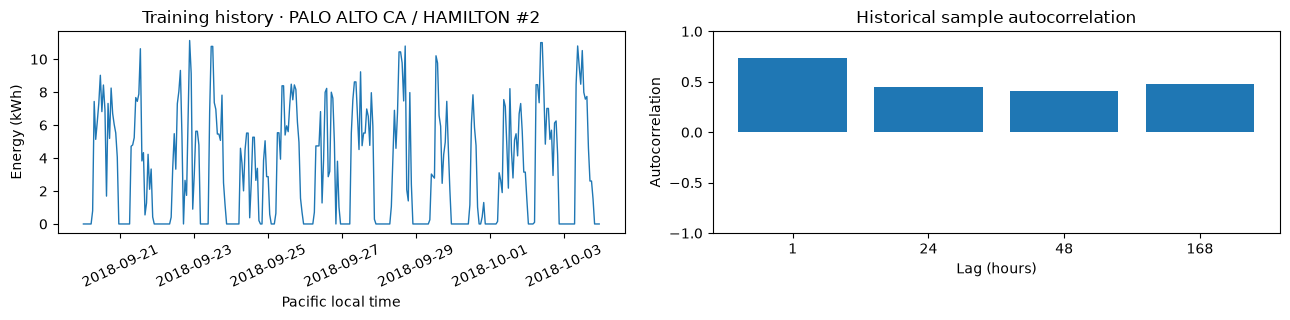

Training hourly energy by hour-of-day, station: PALO ALTO CA / HAMILTON #2


timestamp,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
mean_kWh,0.89,0.7,0.55,0.43,0.37,0.49,1.82,2.59,2.79,2.98,3.27,3.36,3.55,3.42,3.25,3.17,3.0,3.13,3.36,3.14,2.65,2.0,1.54,1.17


In [7]:
targets = panel.loc[panel["eligible_target"]].copy()
daily_counts = targets.groupby("date", observed=True).size().sort_index()
if len(daily_counts) < 40:
    raise ValueError("Too few eligible dates to create reliable train/validation/test periods.")
total_targets = int(daily_counts.sum())
train_count_cumulative = daily_counts.cumsum()
# Keep complete days; choose the midnight closest to a 70% observation split.
train_last_day = (train_count_cumulative - .70 * total_targets).abs().idxmin()
train = targets.loc[targets["date"] <= train_last_day].copy()
test = targets.loc[targets["date"] > train_last_day].copy()
if train.empty or test.empty:
    raise ValueError("Empty chronological train or test subset.")
assert train["timestamp"].max() < test["timestamp"].min()
assert len(train) + len(test) == total_targets
# Nested, temporal validation within the initial 70%.
inside_counts = train.groupby("date", observed=True).size().sort_index()
fit_last_day = (inside_counts.cumsum() - (1-VALIDATION_FRACTION_OF_TRAIN) * len(train)).abs().idxmin()
fit_rows = train.loc[train["date"] <= fit_last_day].copy()
val_rows = train.loc[train["date"] > fit_last_day].copy()
if fit_rows.empty or val_rows.empty:
    raise ValueError("Inner training/validation period is empty.")
assert fit_rows["timestamp"].max() < val_rows["timestamp"].min()

print(f"Initial train: {len(train):,} ({len(train)/total_targets:.2%}), through {train_last_day.date()}")
print(f"  - Model-fitting: {len(fit_rows):,}; through {fit_last_day.date()}")
print(f"  - Validation:    {len(val_rows):,}; after {fit_last_day.date()}")
print(f"Final test:    {len(test):,} ({len(test)/total_targets:.2%}), from {test['date'].min().date()}")
print("Train / test stations:", train["station"].nunique(), "/", test["station"].nunique())
print("All subsets contain only complete 24-hour station-days:",
      bool(train.groupby(["station", "date"], observed=True).size().eq(24).all() and
           test.groupby(["station", "date"], observed=True).size().eq(24).all()))

# Diagnostics: pick a station using initial-training information only.
main_station = train.groupby("station", observed=True)["energy_kwh"].sum().idxmax()
sub = (panel.loc[panel["station"].eq(main_station) & panel["date"].le(train_last_day)]
       .sort_values("timestamp").set_index("timestamp"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.3))
window = sub["energy_kwh"].iloc[-24*14:]
axes[0].plot(window.index, window, linewidth=1)
axes[0].set(title=f"Training history · {main_station}", ylabel="Energy (kWh)", xlabel="Pacific local time")
for tick in axes[0].get_xticklabels(): tick.set_rotation(25)
acf_lags = [1, 24, 48, 168]
acf_values = [sub["energy_kwh"].autocorr(lag=k) for k in acf_lags]
axes[1].bar([str(k) for k in acf_lags], acf_values)
axes[1].set(title="Historical sample autocorrelation", xlabel="Lag (hours)", ylabel="Autocorrelation", ylim=(-1, 1))
plt.tight_layout()
plt.show()
print("Training hourly energy by hour-of-day, station:", main_station)
display(sub.groupby(sub.index.hour)["energy_kwh"].mean().rename("mean_kWh").to_frame().T.round(2))

## 8. Historical average benchmark
The required benchmark predicts energy from the average consumption of the **same station, weekday and hour** in the training data. For example, the forecast for a station on Monday at 10:00 is based on its earlier Mondays at 10:00.

$$\widehat{E}^{\,base}_{s,w,h}=\operatorname{mean}_{t\in\text{training},\ (s,w,h)} E_t.$$

If a station has too few records for this exact combination, a more general average is used, starting with the station-hour average. This gives a prediction even when some historical combinations are missing.

In [8]:
def fit_historical_baseline(history):
    return {
        "swh": history.groupby(["station", "dow", "hour"], observed=True)["energy_kwh"].mean(),
        "sh": history.groupby(["station", "hour"], observed=True)["energy_kwh"].mean(),
        "s": history.groupby("station", observed=True)["energy_kwh"].mean(),
        "all": float(history["energy_kwh"].mean()),
    }

def predict_historical_baseline(ref, future_rows):
    k1 = pd.MultiIndex.from_frame(future_rows[["station", "dow", "hour"]])
    k2 = pd.MultiIndex.from_frame(future_rows[["station", "hour"]])
    vals = pd.Series(ref["swh"].reindex(k1).to_numpy(), index=future_rows.index, dtype=float)
    vals = vals.fillna(pd.Series(ref["sh"].reindex(k2).to_numpy(), index=future_rows.index))
    vals = vals.fillna(future_rows["station"].map(ref["s"]).astype(float))
    vals = vals.fillna(ref["all"]).clip(lower=0)
    assert vals.notna().all()
    return vals.to_numpy(dtype=float)

inner_baseline = fit_historical_baseline(fit_rows)
validation_baseline = predict_historical_baseline(inner_baseline, val_rows)
print("Validation benchmark MAE (kWh):", round(mean_absolute_error(val_rows["energy_kwh"], validation_baseline), 4))

Validation benchmark MAE (kWh): 1.5435


## 9. Forecasting models and model choice
Three machine-learning versions are compared: **Ridge Regression** and two settings of **Gradient Boosting**. Ridge is a linear model with regularization. Gradient Boosting can describe more complex relationships between time, station and past energy use.

The models use one combined dataset from all stations, with station identity included as a variable. The best model is selected using **validation MAE**, where lower values mean better predictions. On validation, regularized Gradient Boosting has the lowest MAE (**1.2743 kWh**), followed by flexible Gradient Boosting (**1.2769 kWh**) and Ridge (**1.3056 kWh**). The historical average has a validation MAE of **1.5435 kWh**. Therefore, regularized Gradient Boosting is selected for final testing.

In [9]:
ridge_preparation = ColumnTransformer(
    transformers=[
        ("station", OneHotEncoder(handle_unknown="ignore"), ["station"]),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler())
        ]), NUMERIC_FEATURES),
    ],
    sparse_threshold=1.0,
)

CANDIDATES = {
    "Ridge (linear)": (
        Pipeline([("prepare", ridge_preparation), ("regressor", Ridge(alpha=40.0, solver="lsqr"))]),
        RIDGE_FEATURES),
    "Gradient boosting (regularized)": (
        HistGradientBoostingRegressor(
            loss="squared_error", learning_rate=0.07, max_iter=140,
            max_leaf_nodes=20, min_samples_leaf=50, l2_regularization=5.0,
            categorical_features=["station_code"], early_stopping=False, random_state=SEED
        ), BOOST_FEATURES),
    "Gradient boosting (flexible)": (
        HistGradientBoostingRegressor(
            loss="squared_error", learning_rate=0.07, max_iter=160,
            max_leaf_nodes=31, min_samples_leaf=25, l2_regularization=1.0,
            categorical_features=["station_code"], early_stopping=False, random_state=SEED
        ), BOOST_FEATURES),
}

validation_results = [{"model": "Historical weekday-hour average", "validation_MAE_kWh":
                       float(mean_absolute_error(val_rows["energy_kwh"], validation_baseline))}]
for name, (candidate, columns) in CANDIDATES.items():
    fitted = clone(candidate)
    fitted.fit(fit_rows[columns], fit_rows["energy_kwh"])
    estimated = np.maximum(fitted.predict(val_rows[columns]), 0.0)
    validation_results.append({"model": name, "validation_MAE_kWh":
                               float(mean_absolute_error(val_rows["energy_kwh"], estimated))})
validation_table = pd.DataFrame(validation_results).sort_values("validation_MAE_kWh")
display(validation_table.round(4))

machine_results = validation_table.loc[validation_table["model"].isin(CANDIDATES)]
CHOSEN_NAME = machine_results.iloc[0]["model"]
print("Chosen predictive model, decided ONLY by validation MAE:", CHOSEN_NAME)
print("If all predictive candidates lose against the baseline, model selection alone cannot certify the assignment's benchmark target.")

,model,validation_MAE_kWh
2,Gradient boosting (regularized),1.2743
3,Gradient boosting (flexible),1.2769
1,Ridge (linear),1.3056
0,Historical weekday-hour average,1.5435


Chosen predictive model, decided ONLY by validation MAE: Gradient boosting (regularized)
If all predictive candidates lose against the baseline, model selection alone cannot certify the assignment's benchmark target.


## 10. Final training and day-ahead predictions
After selecting the model, it is trained again using the full first 70% of the data. The historical average is also calculated from this same training period.

In the test period, each day's forecast uses the information that would have been available by the previous midnight. The trained model stays the same during testing, but the previous day's observed consumption can be used for the next forecast. This represents a **day-ahead forecast that is updated with recent information**, rather than a forecast for several months made all at once.

In [10]:
chosen_estimator, chosen_cols = CANDIDATES[CHOSEN_NAME]
chosen_model = clone(chosen_estimator)
chosen_model.fit(train[chosen_cols], train["energy_kwh"])
full_train_baseline = fit_historical_baseline(train)
test["baseline_kwh"] = predict_historical_baseline(full_train_baseline, test)
test["forecast_kwh"] = np.maximum(chosen_model.predict(test[chosen_cols]), 0.0)
assert test[["baseline_kwh", "forecast_kwh"]].notna().all().all()
assert (test[["baseline_kwh", "forecast_kwh"]] >= 0).all().all()

# Also refit Ridge separately for a transparent linear-vs-nonlinear test comparison.
# This is diagnostic only: CHOSEN_NAME is NOT reconsidered using test error.
ridge_model = clone(CANDIDATES["Ridge (linear)"][0])
if CHOSEN_NAME == "Ridge (linear)":
    ridge_model = chosen_model
gb_name = CHOSEN_NAME if CHOSEN_NAME.startswith("Gradient boosting") else           "Gradient boosting (regularized)"
gb_model = chosen_model if CHOSEN_NAME == gb_name else clone(CANDIDATES[gb_name][0])
if ridge_model is not chosen_model:
    ridge_model.fit(train[RIDGE_FEATURES], train["energy_kwh"])
if gb_model is not chosen_model:
    gb_model.fit(train[BOOST_FEATURES], train["energy_kwh"])
test["ridge_kwh"] = np.maximum(ridge_model.predict(test[RIDGE_FEATURES]), 0.0)
test["boosting_kwh"] = np.maximum(gb_model.predict(test[BOOST_FEATURES]), 0.0)

assert (test["timestamp"].min() > train["timestamp"].max())
assert test.groupby(["station", "date"], observed=True).size().eq(24).all()
print("Final test prediction rows:", f"{len(test):,}", "| Frozen selected model:", CHOSEN_NAME)

Final test prediction rows: 386,904 | Frozen selected model: Gradient boosting (regularized)


## 11. Forecast performance
The models are evaluated on the same **386,904 test station-hours**. Three measures are used: **MAE** (average absolute error), **RMSE** (which gives more weight to large errors), and **WAPE** (total absolute error compared with total observed energy). Lower values are better.

| Model | MAE (kWh) | RMSE (kWh) | WAPE (%) |
|:--|--:|--:|--:|
| Historical weekday-hour average | 1.5012 | 2.1613 | 95.73 |
| Ridge Regression | 1.4666 | 2.1255 | 93.53 |
| Gradient Boosting | **1.3891** | **2.0649** | **88.59** |

Gradient Boosting reduces MAE by **7.47%** compared with the required historical average. It performs better than the benchmark at **25 of the 33 stations**. However, the benchmark is still better at eight stations, and the WAPE shows that prediction errors remain important.

In [11]:
def error_metrics(actual, predicted):
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    if not len(a) or not np.isfinite(a).all() or not np.isfinite(p).all():
        raise ValueError("Model evaluation has missing/non-finite values or an empty sample.")
    denom = np.abs(a).sum()
    return {"MAE_kWh": float(mean_absolute_error(a, p)),
            "RMSE_kWh": float(np.sqrt(mean_squared_error(a, p))),
            "WAPE_pct": float(100 * np.abs(a-p).sum()/denom) if denom > 0 else np.nan}

DISPLAY_MODELS = {"Historical weekday-hour average": "baseline_kwh",
                  "Ridge": "ridge_kwh", "Gradient boosting": "boosting_kwh",
                  f"Selected · {CHOSEN_NAME}": "forecast_kwh"}
performance = pd.DataFrame({label: error_metrics(test["energy_kwh"], test[col])
                            for label, col in DISPLAY_MODELS.items()}).T
baseline_mae = float(performance.loc["Historical weekday-hour average", "MAE_kWh"])
selected_mae = float(performance.loc[f"Selected · {CHOSEN_NAME}", "MAE_kWh"])
relative_gain = ((baseline_mae - selected_mae)/baseline_mae*100) if baseline_mae else np.nan
BENCHMARK_PASSED = bool(selected_mae < baseline_mae)
print("FINAL TEST performance (lower is better; these figures were NOT used to pick a model)")
display(performance.round(4))
print(f"Selected model MAE vs required benchmark: {relative_gain:+.2f}% error reduction")
print("ASSIGNMENT BENCHMARK:", "PASSED" if BENCHMARK_PASSED else "NOT MET — additional validation-only development required")

station_rows = []
for st, group in test.groupby("station", observed=True):
    m_base = error_metrics(group["energy_kwh"], group["baseline_kwh"])
    m_model = error_metrics(group["energy_kwh"], group["forecast_kwh"])
    station_rows.append({"station": str(st), "test_hours": len(group),
                         "test_days": group["date"].nunique(),
                         "baseline_MAE_kWh": m_base["MAE_kWh"],
                         "selected_MAE_kWh": m_model["MAE_kWh"],
                         "baseline_RMSE_kWh": m_base["RMSE_kWh"],
                         "selected_RMSE_kWh": m_model["RMSE_kWh"],
                         "selected_WAPE_pct": m_model["WAPE_pct"],
                         "beats_baseline_MAE": m_model["MAE_kWh"] < m_base["MAE_kWh"]})
station_metrics = pd.DataFrame(station_rows).sort_values("selected_MAE_kWh")
print("Stations with lower MAE than baseline:", int(station_metrics["beats_baseline_MAE"].sum()),
      "/", len(station_metrics))
display(station_metrics.round(3))

hour_rows = []
for h, group in test.groupby("hour", observed=True):
    hour_rows.append({"hour": int(h),
                      "baseline_MAE_kWh": mean_absolute_error(group["energy_kwh"], group["baseline_kwh"]),
                      "selected_MAE_kWh": mean_absolute_error(group["energy_kwh"], group["forecast_kwh"])})
hour_metrics = pd.DataFrame(hour_rows).sort_values("hour")
assert set(hour_metrics["hour"]) == set(range(24))

FINAL TEST performance (lower is better; these figures were NOT used to pick a model)


,MAE_kWh,RMSE_kWh,WAPE_pct
Historical weekday-hour average,1.5012,2.1613,95.7330
Ridge,1.4666,2.1255,93.5273
Gradient boosting,1.3891,2.0649,88.5864
Selected · Gradient boosting (regularized),1.3891,2.0649,88.5864


Selected model MAE vs required benchmark: +7.47% error reduction
ASSIGNMENT BENCHMARK: PASSED
Stations with lower MAE than baseline: 25 / 33


,station,test_hours,test_days,baseline_MAE_kWh,selected_MAE_kWh,baseline_RMSE_kWh,selected_RMSE_kWh,selected_WAPE_pct,beats_baseline_MAE
19,PALO ALTO CA / MPL #3,6984,291,0.350,0.179,0.534,0.375,824.632,True
17,PALO ALTO CA / MPL #1,5592,233,0.296,0.202,0.626,0.566,362.788,True
18,PALO ALTO CA / MPL #2,9048,377,0.428,0.258,0.745,0.655,316.234,True
2,PALO ALTO CA / BRYANT #3,12240,510,1.176,1.055,1.613,1.591,123.203,True
0,PALO ALTO CA / BRYANT #1,12240,510,1.306,1.065,1.657,1.560,113.401,True
29,PALO ALTO CA / TED THOMPSON #4,12240,510,1.041,1.084,1.933,1.839,92.408,False
1,PALO ALTO CA / BRYANT #2,12216,509,1.375,1.135,1.728,1.628,113.641,True
11,PALO ALTO CA / HAMILTON #1,12240,510,1.286,1.162,1.629,1.570,86.794,True
7,PALO ALTO CA / CAMBRIDGE #2,12240,510,1.596,1.169,2.058,1.731,107.089,True
28,PALO ALTO CA / TED THOMPSON #3,12240,510,1.189,1.237,2.092,2.013,93.508,False


## 12. Hourly errors and an example day
The figures below compare actual hourly energy with the historical average and Gradient Boosting predictions. The example is from **Hamilton #2 on 28 February 2020**. It shows how the models follow the daily pattern and where they miss changes in demand.

The error plots also show that performance is not the same at every hour. The largest average MAE for the selected model occurs at **11:00**. Large changes in charging demand, especially during busy hours, are still difficult to predict exactly.

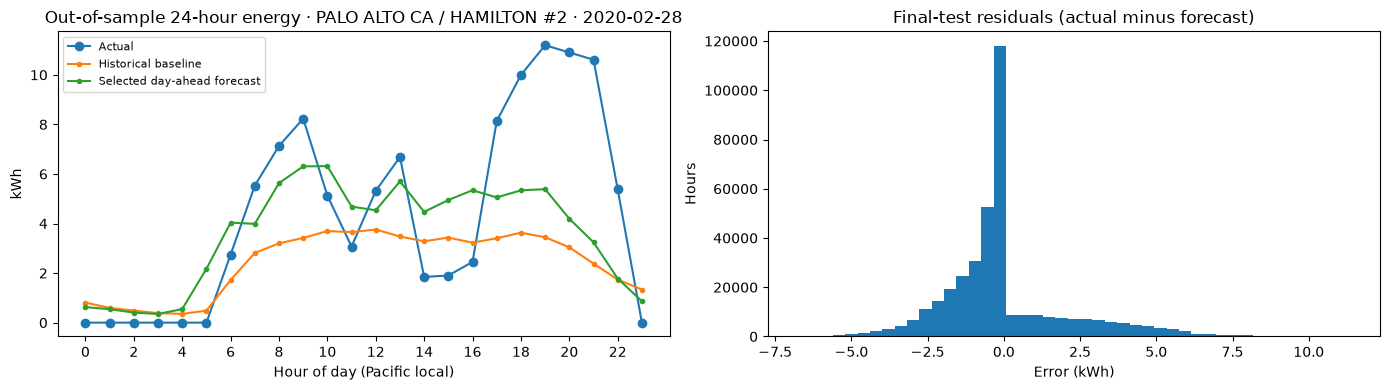

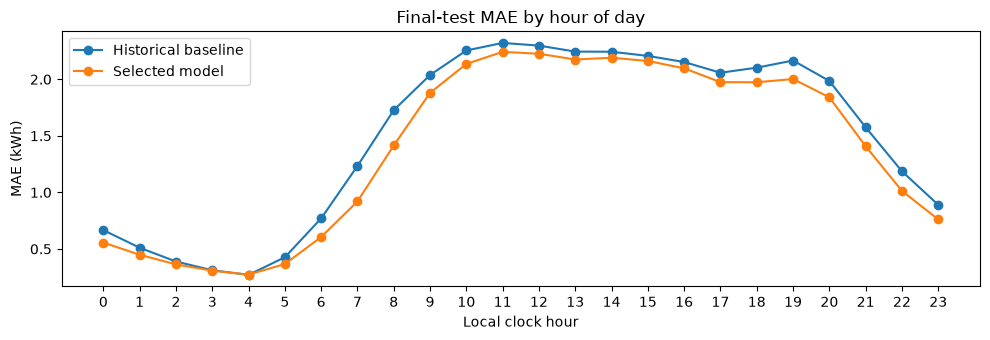

C:\Users\User\AppData\Local\Temp\ipykernel_25448\2888243165.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(sample_day[["timestamp", "energy_kwh", "baseline_kwh", "forecast_kwh"]].round(3))


,timestamp,energy_kwh,baseline_kwh,forecast_kwh
526818,2020-02-28 00:00:00,0.000,0.808,0.627
526819,2020-02-28 01:00:00,0.000,0.594,0.542
526820,2020-02-28 02:00:00,0.000,0.485,0.405
526821,2020-02-28 03:00:00,0.000,0.383,0.347
526822,2020-02-28 04:00:00,0.000,0.354,0.547
526823,2020-02-28 05:00:00,0.000,0.483,2.171
526824,2020-02-28 06:00:00,2.742,1.722,4.036
526825,2020-02-28 07:00:00,5.531,2.812,3.986
526826,2020-02-28 08:00:00,7.130,3.198,5.630
526827,2020-02-28 09:00:00,8.235,3.419,6.306


Largest MAE hour for selected model: 11


In [12]:
plot_station = str(main_station)
plot_data = test.loc[test["station"].astype(str).eq(plot_station)].copy()
full_days = plot_data.groupby("date", observed=True).size()
full_days = full_days.loc[full_days.eq(24)]
if full_days.empty:
    # Choose the most represented test station without looking at model errors.
    plot_station = str(test["station"].value_counts().index[0])
    plot_data = test.loc[test["station"].astype(str).eq(plot_station)].copy()
    full_days = plot_data.groupby("date", observed=True).size()
    full_days = full_days.loc[full_days.eq(24)]
if full_days.empty:
    raise ValueError("No 24-hour test day could be plotted.")
plot_day = full_days.index[-1]
sample_day = plot_data.loc[plot_data["date"].eq(plot_day)].sort_values("hour")
assert len(sample_day) == 24

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(sample_day["hour"], sample_day["energy_kwh"], "o-", label="Actual")
axes[0].plot(sample_day["hour"], sample_day["baseline_kwh"], ".-", label="Historical baseline")
axes[0].plot(sample_day["hour"], sample_day["forecast_kwh"], ".-", label="Selected day-ahead forecast")
axes[0].set(title=f"Out-of-sample 24-hour energy · {plot_station} · {plot_day.date()}",
            xlabel="Hour of day (Pacific local)", ylabel="kWh", xticks=list(range(0, 24, 2)))
axes[0].legend(fontsize=8)
residuals = test["energy_kwh"].to_numpy() - test["forecast_kwh"].to_numpy()
axes[1].hist(residuals, bins=45)
axes[1].set(title="Final-test residuals (actual minus forecast)", xlabel="Error (kWh)", ylabel="Hours")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(hour_metrics["hour"], hour_metrics["baseline_MAE_kWh"], "o-", label="Historical baseline")
ax.plot(hour_metrics["hour"], hour_metrics["selected_MAE_kWh"], "o-", label="Selected model")
ax.set(title="Final-test MAE by hour of day", xlabel="Local clock hour", ylabel="MAE (kWh)", xticks=list(range(24)))
ax.legend()
plt.tight_layout()
plt.show()

display(sample_day[["timestamp", "energy_kwh", "baseline_kwh", "forecast_kwh"]].round(3))
print("Largest MAE hour for selected model:", int(hour_metrics.loc[hour_metrics["selected_MAE_kWh"].idxmax(), "hour"]))

## 13. Example: a full 24-hour forecast
The final example gives a forecast for **29 February 2020**, using information available before **00:00** on that date. It produces **24 hourly predictions for each of the 33 stations**, or **792 predictions** in total.

The forecast for each hour is shown together with the historical-average prediction. Where available, the energy observed later on the same day is included for comparison only. It is not used to create the forecast.

In [13]:
forecast_date = ev["start"].max().normalize()
if forecast_date <= test["date"].min():
    forecast_date = test["date"].max()
forecast_origin_end = forecast_date  # 00:00, before the entire target date.
forecast_clock_hours = pd.date_range(forecast_date, periods=24, freq="h")
future_rows = pd.MultiIndex.from_product([STATIONS, forecast_clock_hours],
                                         names=["station", "timestamp"]).to_frame(index=False)
future_rows["station"] = future_rows["station"].astype("category")
future_rows["energy_kwh"] = np.float32(np.nan)
future_rows["confirmed_by_next_midnight_kwh"] = np.float32(np.nan)
# Remove target-day outcomes and all later data from the history. Full prior days only.
prior = panel.loc[panel["timestamp"] < forecast_origin_end,
                  ["station", "timestamp", "energy_kwh", "confirmed_by_next_midnight_kwh"]].copy()
# Preallocate as the same float32 dtype as the existing station series.
# Concatenate only after setting stable schemas; avoids all-NA dtype warnings.
future_matrix = pd.concat([prior, future_rows], ignore_index=True)
future_features = make_features(future_matrix)
forecast_today = future_features.loc[future_features["timestamp"].ge(forecast_date)].copy()
assert len(forecast_today) == len(STATIONS)*24
assert forecast_today.groupby("station", observed=True).size().eq(24).all()
assert forecast_today["energy_kwh"].isna().all()
forecast_today["prediction_kwh"] = np.maximum(chosen_model.predict(forecast_today[chosen_cols]), 0.0)
forecast_today["baseline_kwh"] = predict_historical_baseline(full_train_baseline, forecast_today)

# Status flag only; training/forecast features do not use observed future availability.
lookback_start = forecast_date - pd.Timedelta(days=30)
recent_stations = set(ev.loc[(ev["start"] >= lookback_start) & (ev["start"] < forecast_date), "station"].astype(str))
forecast_today["recent_observation_30d"] = forecast_today["station"].astype(str).isin(recent_stations)

# Join actual outcomes ONLY after all predictions have been generated and frozen.
realized = panel.loc[panel["date"].eq(forecast_date), ["station", "timestamp", "energy_kwh"]]
realized = realized.rename(columns={"energy_kwh": "observed_after_forecast_kwh"})
forecast_24h = forecast_today[["station", "timestamp", "prediction_kwh", "baseline_kwh",
                               "recent_observation_30d"]].merge(
    realized, on=["station", "timestamp"], how="left", validate="one_to_one")
forecast_24h = forecast_24h.sort_values(["station", "timestamp"]).reset_index(drop=True)
assert len(forecast_24h) == len(STATIONS) * 24
print(f"As-of forecast issue time: {forecast_origin_end} Pacific local")
print(f"Forecast date: {forecast_date.date()} | Stations: {len(STATIONS)} | 24 hourly predictions each")
print("Stations observed in prior 30 days:", len(recent_stations))
display(forecast_24h.head(24).round(3))

As-of forecast issue time: 2020-02-29 00:00:00 Pacific local
Forecast date: 2020-02-29 | Stations: 33 | 24 hourly predictions each
Stations observed in prior 30 days: 33


C:\Users\User\AppData\Local\Temp\ipykernel_25448\1951149349.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast_24h.head(24).round(3))


,station,timestamp,prediction_kwh,baseline_kwh,recent_observation_30d,observed_after_forecast_kwh
0,PALO ALTO CA / BRYANT #1,2020-02-29 00:00:00,0.214,0.455,True,0.000
1,PALO ALTO CA / BRYANT #1,2020-02-29 01:00:00,0.157,0.343,True,0.000
2,PALO ALTO CA / BRYANT #1,2020-02-29 02:00:00,0.137,0.221,True,0.000
3,PALO ALTO CA / BRYANT #1,2020-02-29 03:00:00,0.109,0.183,True,0.000
4,PALO ALTO CA / BRYANT #1,2020-02-29 04:00:00,0.061,0.126,True,0.000
5,PALO ALTO CA / BRYANT #1,2020-02-29 05:00:00,0.055,0.126,True,0.000
6,PALO ALTO CA / BRYANT #1,2020-02-29 06:00:00,0.055,0.302,True,0.000
7,PALO ALTO CA / BRYANT #1,2020-02-29 07:00:00,0.102,0.578,True,0.000
8,PALO ALTO CA / BRYANT #1,2020-02-29 08:00:00,0.464,0.835,True,0.000
9,PALO ALTO CA / BRYANT #1,2020-02-29 09:00:00,0.644,1.158,True,0.000


## 14. Long gaps in station records
The station activity data contain **15 gaps longer than 30 days**. Together, these gaps cover about **994.2 station-days**, and **23,847 station-hours** are marked as outside the active periods. They are excluded from the main model evaluation rather than counted as hours with zero energy use.

A long period without a recorded session does not prove that a charger was out of service. The activity rule is therefore an assumption that may affect which hours are included in the study.

In [14]:
gap_summary = []
for st in STATIONS:
    row = activity.loc[st]
    gaps = row["gaps"] if isinstance(row["gaps"], (list, tuple)) else []
    gap_summary.append({"station": st, "inferred_gaps_over_30d": len(gaps),
                        "inferred_total_gap_days": sum((pd.Timestamp(b)-pd.Timestamp(a)).total_seconds()/86400
                                                       for a, b in gaps)})
gap_summary = pd.DataFrame(gap_summary)
print("Total retrospectively inferred long gaps:", gap_summary["inferred_gaps_over_30d"].sum())
print("Sum of gap days across stations:", round(gap_summary["inferred_total_gap_days"].sum(), 1))
print("Number of excluded station-hours:", int((~panel["active"]).sum()))
print("This is an eligibility/data-quality sensitivity, not a test-set hyperparameter search.")
display(gap_summary.sort_values("inferred_total_gap_days", ascending=False).head(10).round(1))

Total retrospectively inferred long gaps: 15
Sum of gap days across stations: 994.2
Number of excluded station-hours: 23847
This is an eligibility/data-quality sensitivity, not a test-set hyperparameter search.


,station,inferred_gaps_over_30d,inferred_total_gap_days
17,PALO ALTO CA / MPL #1,4,283.6
19,PALO ALTO CA / MPL #3,3,214.2
21,PALO ALTO CA / MPL #5,2,141.1
18,PALO ALTO CA / MPL #2,2,128.4
20,PALO ALTO CA / MPL #4,2,111.8
22,PALO ALTO CA / MPL #6,1,82.2
8,PALO ALTO CA / CAMBRIDGE #3,1,33.0
0,PALO ALTO CA / BRYANT #1,0,0.0
1,PALO ALTO CA / BRYANT #2,0,0.0
9,PALO ALTO CA / CAMBRIDGE #4,0,0.0


## 15. Results and output data
The final test contains **386,904 hourly predictions** for all 33 stations. The separate day-ahead example contains **792 predictions**, covering 24 hours at each station. The checks confirm that the forecast rows have no duplicate station-hour combinations and that the time split is in the correct order.

The output tables include overall model errors, station-level and hour-level errors, validation results, test predictions, the 24-hour example and the identified long gaps. They are saved in `Data/forecast_outputs/`.

In [15]:
assert len(forecast_24h) == 24 * len(STATIONS)
assert not forecast_24h.duplicated(["station", "timestamp"]).any()
assert np.isfinite(forecast_24h[["prediction_kwh", "baseline_kwh"]].to_numpy()).all()
assert (forecast_24h[["prediction_kwh", "baseline_kwh"]].to_numpy() >= 0).all()
assert not test.duplicated(["station", "timestamp"]).any()
assert train["timestamp"].max() < test["timestamp"].min()
assert test["eligible_target"].all()
assert test["hour"].between(0, 23).all()
assert test.groupby(["station", "date"], observed=True).size().eq(24).all()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_test = test[["station", "timestamp", "date", "hour", "energy_kwh",
                    "baseline_kwh", "ridge_kwh", "boosting_kwh", "forecast_kwh"]].copy()
export_test.to_csv(OUTPUT_DIR / "forecast_test_predictions.csv", index=False)
forecast_24h.to_csv(OUTPUT_DIR / "forecast_day_ahead_24h.csv", index=False)
station_metrics.to_csv(OUTPUT_DIR / "forecast_station_metrics.csv", index=False)
hour_metrics.to_csv(OUTPUT_DIR / "forecast_hourly_metrics.csv", index=False)
performance.rename_axis("model").reset_index().to_csv(OUTPUT_DIR / "forecast_overall_metrics.csv", index=False)
validation_table.to_csv(OUTPUT_DIR / "forecast_validation_models.csv", index=False)
gap_summary.to_csv(OUTPUT_DIR / "forecast_inferred_gaps.csv", index=False)

print("PASS: conservation, anti-leakage, target eligibility, split, and 24-hour export assertions.")
print("OUTPUT DIRECTORY:", OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.glob("forecast_*.csv")):
    print("  ", path.name, f"({path.stat().st_size:,} bytes)")
print("\nFACTS FOR TEAM REPORT:")
print(f"Full cleaned time window: {START_DAY.date()} through {(END_EXCLUSIVE-pd.Timedelta(days=1)).date()}")
print(f"Chronological split: {len(train)/total_targets:.2%} training / {len(test)/total_targets:.2%} test")
print(f"Model chosen on validation: {CHOSEN_NAME}")
print(f"Test MAE baseline: {baseline_mae:.4f} kWh | chosen: {selected_mae:.4f} kWh")
print(f"Improvement in MAE vs baseline: {relative_gain:+.2f}% | benchmark met: {BENCHMARK_PASSED}")
print(f"Stations beating baseline: {station_metrics['beats_baseline_MAE'].sum()} of {len(station_metrics)}")

PASS: conservation, anti-leakage, target eligibility, split, and 24-hour export assertions.
OUTPUT DIRECTORY: C:\Users\User\Documents\DTU\1st Term\42577 Introduction to Business Analytics\Introduction-to-Business-Analytics-main\Data\forecast_outputs
   forecast_day_ahead_24h.csv (74,276 bytes)
   forecast_hourly_metrics.csv (1,028 bytes)
   forecast_inferred_gaps.csv (1,251 bytes)
   forecast_overall_metrics.csv (358 bytes)
   forecast_station_metrics.csv (4,611 bytes)
   forecast_test_predictions.csv (54,350,765 bytes)
   forecast_validation_models.csv (213 bytes)

FACTS FOR TEAM REPORT:
Full cleaned time window: 2011-07-29 through 2020-02-29
Chronological split: 69.98% training / 30.02% test
Model chosen on validation: Gradient boosting (regularized)
Test MAE baseline: 1.5012 kWh | chosen: 1.3891 kWh
Improvement in MAE vs baseline: +7.47% | benchmark met: True
Stations beating baseline: 25 of 33


## 16. Conclusion and limitations
**Gradient Boosting gave the best overall day-ahead predictions.** Its test MAE was **1.3891 kWh**, compared with **1.5012 kWh** for the historical average. This is a **7.47% improvement**, so the model meets the required benchmark. It also gives lower MAE at **25 of 33 stations**. Still, the WAPE is **88.59%**, and the historical average works better at eight stations.

The hourly energy values are estimates based on total charging-session energy, not direct hourly measurements. A constant charging rate was assumed, so short changes in power may not be represented well. Some long periods without records were excluded as possible data gaps, and daylight-saving transition days were not used as prediction targets. The data also end in February 2020, so charging patterns today may be different.

These forecasts could help a charging provider estimate its hourly energy needs. However, the errors during busy hours mean they should be used with care, especially when exact peak demand is important.